# 00 · Boceto: trazado vectorial en una lente gruesa

Primer recorrido completo del método con el paquete `lentes` (la física vive en `src/lentes`; este notebook solo la usa):

1. definir la lente (cara $y=g(x)$ abajo y cara $y=f(x)$ arriba) y un punto objeto $P$;
2. trazar **dos rayos** con sus **dos refracciones** (actividad 3);
3. hallar la imagen como **cruce de los rayos emergentes**;
4. compararla con la predicción **paraxial** (lente gruesa y lente delgada) y ver la **aberración esférica**.

Convenciones: el eje óptico es el eje $y$ y la luz viaja en $+y$ ([decisión 0001](../docs/decisiones/0001-eje-optico-y-sentido-de-la-luz.md)); en cada cara la normal se orienta hacia el medio de donde viene la luz ([decisión 0002](../docs/decisiones/0002-normal-y-snell-vectorial.md)).

Usamos una lente con caras parabólicas, radio de vértice $R = 10$, espesor $2$ y $n_L = 1.5$:

$$g(x) = -1 + \frac{x^2}{20}, \qquad f(x) = 1 - \frac{x^2}{20}.$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from lentes import (cruce_con_eje, focal_efectiva, imagen_de_dos_rayos, imagen_lente_delgada,
                    imagen_paraxial, lente_biconvexa, rayo_hacia, trazar)
from lentes.estilo import NARANJA, TINTA, SUPERFICIE, aplicar_estilo, color_por_altura
from lentes.graficos import dibujar_lente, dibujar_trayectoria

aplicar_estilo()

lente = lente_biconvexa(R1=10, R2=10, espesor=2, n=1.5, k1=-1, k2=-1)  # k = -1: caras parabólicas
P = np.array([0.0, -30.0])  # punto objeto sobre el eje, 30 unidades debajo del centro de la lente

print(lente)
print(f"Distancia focal efectiva (paraxial, lente gruesa): {focal_efectiva(lente):.4f}")

Lente(n=1.5, espesor=2, semiapertura=4.472, g='g', f='f')
Distancia focal efectiva (paraxial, lente gruesa): 10.3448


## Dos rayos, paso a paso (actividad 3)

Cada rayo sale de $P$ hacia el punto de la cara $g$ con $x = h$. En cada cara se obtiene el punto de impacto $Q$, la normal orientada $\hat n$, los ángulos $\theta_i$ y $\theta_t$ y la nueva dirección (Snell vectorial). Tomamos $h = +1$ y $h = -1$: por simetría, sus rayos emergentes se cruzan sobre el eje.

In [2]:
def detallar(tr, nombre):
    print(f"{nombre}: sale de P = {tr.puntos[0]} con dirección û = {np.round(tr.direcciones[0], 6)}")
    for Q, det, cara in zip(tr.puntos[1:], tr.detalles, tr.caras):
        print(f"  cara {cara}:  Q = {np.round(Q, 6)}   n̂ = {np.round(det.normal, 6)}")
        print(f"           θi = {np.degrees(det.theta_i):8.4f}°   θt = {np.degrees(det.theta_t):8.4f}°"
              f"   nueva dirección = {np.round(det.direccion, 6)}")
    Q, e = tr.salida
    print(f"  el rayo emergente cruza el eje en y = {cruce_con_eje(Q, e):.5f}\n")

rayo_1 = trazar(lente, P, rayo_hacia(lente, P, +1.0))
rayo_2 = trazar(lente, P, rayo_hacia(lente, P, -1.0))
detallar(rayo_1, "Rayo 1 (h = +1)")
detallar(rayo_2, "Rayo 2 (h = -1)")

Rayo 1 (h = +1): sale de P = [  0. -30.] con dirección û = [0.034403 0.999408]
  cara g:  Q = [ 1.   -0.95]   n̂ = [ 0.099504 -0.995037]
           θi =   7.6821°   θt =   5.1129°   nueva dirección = [-0.010432  0.999946]
  cara f:  Q = [0.980158 0.951965]   n̂ = [-0.097548 -0.995231]
           θi =   6.1957°   θt =   9.3165°   nueva dirección = [-0.064854  0.997895]
  el rayo emergente cruza el eje en y = 16.03339

Rayo 2 (h = -1): sale de P = [  0. -30.] con dirección û = [-0.034403  0.999408]
  cara g:  Q = [-1.   -0.95]   n̂ = [-0.099504 -0.995037]
           θi =   7.6821°   θt =   5.1129°   nueva dirección = [0.010432 0.999946]
  cara f:  Q = [-0.980158  0.951965]   n̂ = [ 0.097548 -0.995231]
           θi =   6.1957°   θt =   9.3165°   nueva dirección = [0.064854 0.997895]
  el rayo emergente cruza el eje en y = 16.03339



## La imagen frente a la predicción paraxial (actividad 4)

La imagen es el cruce de los dos rayos emergentes. La comparamos con dos predicciones paraxiales: la de **lente gruesa** (matrices ABCD, que sí tienen en cuenta el espesor) y la de **lente delgada** ($1/s + 1/s' = 1/f$).

In [3]:
img = imagen_de_dos_rayos(rayo_1, rayo_2)
par = imagen_paraxial(lente, P)
delg = imagen_lente_delgada(lente, P)

print(f"Cruce de los rayos 1 y 2:        y = {img.punto[1]:.5f}")
print(f"Paraxial, lente gruesa (ABCD):   y = {par.y:.5f}   -> el trazado difiere en {img.punto[1] - par.y:+.4f}")
print(f"Paraxial, lente delgada:         y = {delg.y:.5f}   -> difiere en {delg.y - par.y:+.4f} solo por ignorar el espesor")

Cruce de los rayos 1 y 2:        y = 16.03339
Paraxial, lente gruesa (ABCD):   y = 16.18717   -> el trazado difiere en -0.1538
Paraxial, lente delgada:         y = 15.00000   -> difiere en -1.1872 solo por ignorar el espesor


## ¿Y si los rayos entran más lejos del eje? (actividad 5)

Repetimos con pares de rayos a alturas $\pm h$ cada vez mayores. Si la imagen dependiera solo de la lente, todos cruzarían en el mismo punto; no es así: los rayos alejados del eje enfocan antes. Eso es la **aberración esférica**, y para $h$ pequeño crece como $h^2$.

In [4]:
for h in (0.25, 0.5, 1.0, 2.0, 3.0, 4.0):
    a = trazar(lente, P, rayo_hacia(lente, P, +h))
    b = trazar(lente, P, rayo_hacia(lente, P, -h))
    y = imagen_de_dos_rayos(a, b).punto[1]
    print(f"h = ±{h:4.2f}  ->  imagen en y = {y:8.4f}   Δy = {y - par.y:+.4f}   Δy/h² = {(y - par.y) / h**2:+.4f}")

h = ±0.25  ->  imagen en y =  16.1776   Δy = -0.0096   Δy/h² = -0.1535
h = ±0.50  ->  imagen en y =  16.1488   Δy = -0.0384   Δy/h² = -0.1535
h = ±1.00  ->  imagen en y =  16.0334   Δy = -0.1538   Δy/h² = -0.1538
h = ±2.00  ->  imagen en y =  15.5677   Δy = -0.6195   Δy/h² = -0.1549
h = ±3.00  ->  imagen en y =  14.7734   Δy = -1.4138   Δy/h² = -0.1571
h = ±4.00  ->  imagen en y =  13.6094   Δy = -2.5778   Δy/h² = -0.1611


## Un segundo punto objeto, fuera del eje

La actividad pide trazar rayos para al menos dos puntos objeto. Con $P_2 = (-1, -30)$ la imagen queda al otro lado del eje (invertida) y su posición también se compara con la paraxial.

In [5]:
P2 = np.array([-1.0, -30.0])
rayo_3 = trazar(lente, P2, rayo_hacia(lente, P2, -0.5))
rayo_4 = trazar(lente, P2, rayo_hacia(lente, P2, +0.5))
img2 = imagen_de_dos_rayos(rayo_3, rayo_4)
par2 = imagen_paraxial(lente, P2)

print(f"Cruce de los rayos 3 y 4:          (x, y) = ({img2.punto[0]:.4f}, {img2.punto[1]:.4f})")
print(f"Paraxial (aumento {par2.aumento:+.4f}):     (x, y) = ({par2.x:.4f}, {par2.y:.4f})")

Cruce de los rayos 3 y 4:          (x, y) = (0.5326, 16.1064)
Paraxial (aumento -0.5348):     (x, y) = (0.5348, 16.1872)


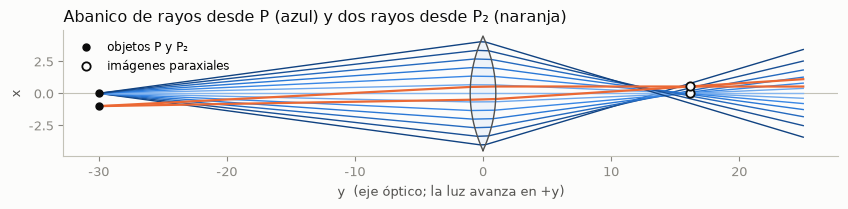

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.4))
dibujar_lente(ax, lente)
ax.axhline(0, color="#c3c2b7", lw=0.8, zorder=0)
a_max = 0.9 * lente.semiapertura
for h in np.linspace(-a_max, a_max, 13):
    dibujar_trayectoria(ax, trazar(lente, P, rayo_hacia(lente, P, h)), y_final=25,
                        color=color_por_altura(h, a_max))
for tr in (rayo_3, rayo_4):
    dibujar_trayectoria(ax, tr, y_final=25, color=NARANJA, lw=1.6)
ax.plot([P[1], P2[1]], [P[0], P2[0]], "o", color=TINTA, ms=5, label="objetos P y P₂")
ax.plot([par.y, par2.y], [par.x, par2.x], "o", mfc=SUPERFICIE, mec=TINTA, ms=6, mew=1.3,
        label="imágenes paraxiales")
ax.set_aspect("equal")
ax.set_xlabel("y  (eje óptico; la luz avanza en +y)")
ax.set_ylabel("x")
ax.set_title("Abanico de rayos desde P (azul) y dos rayos desde P₂ (naranja)", loc="left")
ax.legend(frameon=False, loc="upper left", fontsize=8.5)
plt.show()

## Dónde sigue

- La deducción completa del método (actividades 1 y 2): [`docs/deduccion.md`](../docs/deduccion.md).
- El ejemplo resuelto con dos puntos objeto, calculado con un método independiente: [notebook 01](01_ejemplo_resuelto.ipynb).
- Paraxial frente a vectorial y aberración esférica (actividades 4 y 5): [notebook 02](02_aberraciones.ipynb) y [`docs/aberraciones.md`](../docs/aberraciones.md).
- La simulación con controles (actividad 6): [notebook 03](03_simulacion.ipynb) y la [página web](https://oswaldoaqm.github.io/Proyecto-Opticas/).
- Frente de onda y límite de difracción (extra 5): [notebook 04](04_frente_de_onda.ipynb).